# 8. Newtonian-limit comparisons
For $g_{00}=-(1+2\Phi)$, $g_{ij}=(1-2\Phi)\delta_{ij}$ the linearised Einstein tensor has $G^{(1)}_{00}=2\nabla^2\Phi$, so $G_{00}=8\pi\rho$ is Poisson's equation $\nabla^2\Phi=4\pi\rho$, and $\Gamma^i{}_{00}=\partial_i\Phi$ gives $\ddot x=-\nabla\Phi$.

In [1]:
import sympy as sp
from gr_from_scratch.field_equations.linearized_gravity import linearized_einstein
t, x, y, z = sp.symbols('t x y z', real=True)
Phi = sp.Function('Phi')(x, y, z)
h = sp.diag(-2*Phi, -2*Phi, -2*Phi, -2*Phi)
G = linearized_einstein(h, [t, x, y, z])
lap = sum(sp.diff(Phi, v, 2) for v in (x, y, z))
print('G00 - 2*laplacian(Phi) =', sp.simplify(G[0,0] - 2*lap))

G00 - 2*laplacian(Phi) = 0


**Where does the Newtonian description fail?** For circular orbits Kepler's law holds exactly in Schwarzschild time, but the *proper* period differs by $\sqrt{1-3M/r}$, i.e. a relative correction $\simeq 3M/2r$. We measure it by integrating the geodesic through $\Delta\phi=2\pi$.

max |numeric - exact| = 4.489741911584133e-13


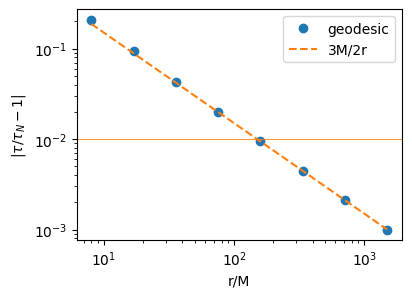

radius where the correction reaches 1% (leading order): r = 150.0 M


In [2]:
import numpy as np, matplotlib.pyplot as plt
from gr_from_scratch.dynamics import observables as ob
from gr_from_scratch.dynamics.geodesics import event_function
gs = ob.schwarzschild_system()
radii = np.logspace(np.log10(8), np.log10(1500), 8)
dev, ex = [], []
for r in radii:
    ut = 1/np.sqrt(1-3/r)
    ev = event_function(3, 2*np.pi, direction=+1, terminal=True)
    tr = gs.integrate(np.array([0,r,np.pi/2,0.]), np.array([ut,0,0,ut/r**1.5]), 3*2*np.pi*r**1.5, rtol=1e-12, atol=1e-13, events=[ev])
    dev.append(tr.sol.t_events[0][0]/(2*np.pi*r**1.5) - 1); ex.append(np.sqrt(1-3/r)-1)
dev = np.array(dev)
print('max |numeric - exact| =', np.abs(dev-np.array(ex)).max())
fig, ax = plt.subplots(figsize=(4.2, 3))
ax.loglog(radii, np.abs(dev), 'o', label='geodesic'); ax.loglog(radii, 1.5/radii, '--', label='3M/2r')
ax.axhline(0.01, color='C1', lw=0.6); ax.set(xlabel='r/M', ylabel=r'$|\tau/\tau_N-1|$'); ax.legend(); plt.show()
print('radius where the correction reaches 1% (leading order): r =', 1.5/0.01, 'M')